# 09 · Steps 5-6: scanner artefacts and normalisation

After the synthesis, the clean image goes through a simulated scanner, always in this order:

| step | module | what it simulates | random parameters |
|---|---|---|---|
| 5a | `bias.py` | smooth intensity inhomogeneity (coil sensitivity) | control values |
| 5b | `motion.py` | head motion between k-space shots (ghosting, blurring) | axis, per-shot pose |
| 5c | `resolution.py` | the acquisition of step 0: slice profile, voxel spacing | none (uses step 0) |
| 5d | `noise.py` | Gaussian noise (on the low-res grid or on the output grid) | sigma, seed |
| 6 | `normalization.py` | rescaling to [0, 1] | none |

The segmentation is never affected by these steps.

In [1]:
from _setup import *
from nxgen.online import bias as B, motion as MO, resolution as RS, noise as NZ
from nxgen.online import normalization as NM, acquisition as A
from nxgen.core.config import load_config
from nxgen import Generator, Recorder

ensure_template()
gen = Generator([TEMPLATE], CONFIG, device=DEVICE)
plan = gen.sample_plan(3)
rec = Recorder(steps=['synthesis'])
gen.render(plan, rec)
clean = rec.steps['synthesis'].to(DEVICE)       # the image after step 4 (tree units / 255)
shape = list(clean.shape)
print('clean image', shape, f'range [{float(clean.min()):.2f}, {float(clean.max()):.2f}]')

clean image [239, 439, 289] range [-0.00, 0.87]


## 5a. Bias field

`image * (1 + B(x))`, with `B` a cubic B-spline (the same code as the elastic field, notebook 06)
of `ctrl³` control values drawn in `U(-vmax, vmax)`. The B-spline is a convex combination, so the
field stays in `[1 - vmax, 1 + vmax]`.

The field is defined over the **whole** output volume and evaluated only on the region being
generated: a patch gets exactly the crop of the full-volume field.

{'prob': 1.0, 'vmax': 0.5, 'ctrl': 5}
params: {'ctrl_values': (5, 5, 5), 'vmax': 0.5}
field range [0.785, 1.329]


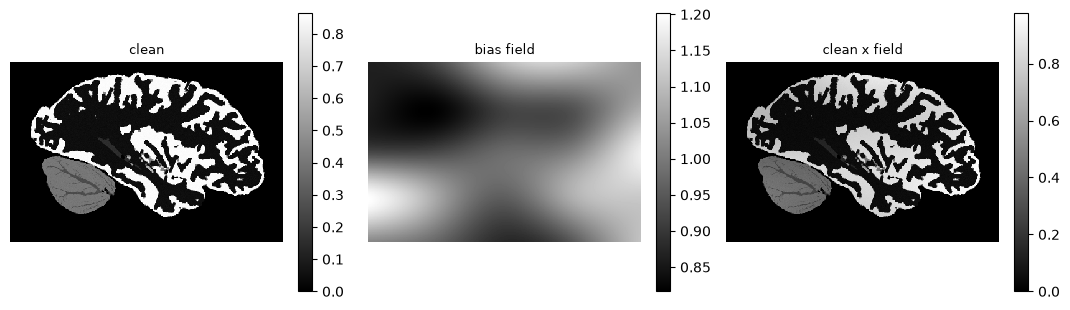

In [2]:
cfg = load_config(CONFIG)['bias']
print(cfg)
pb = B.sample(cfg, np.random.default_rng(0))
print('params:', {k: (np.asarray(v).shape if k == 'ctrl_values' else v) for k, v in pb.items()})
field = B.field(pb, [0, 0, 0], shape, shape, DEVICE)
print(f'field range [{float(field.min()):.3f}, {float(field.max()):.3f}]')
biased = B.apply(clean, pb, [0, 0, 0], shape)
show([clean, field, biased], ['clean', 'bias field', 'clean x field'], axis=0, colorbar=True, size=3.6)

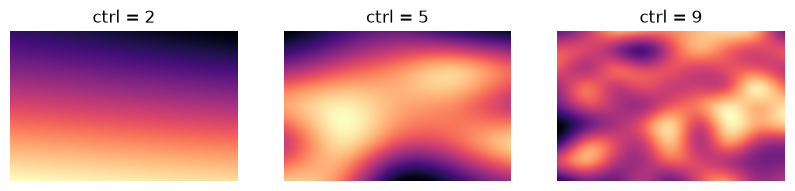

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3))
for a, n in zip(ax, (2, 5, 9)):
    f = B.field(B.sample(dict(cfg, ctrl=n), np.random.default_rng(1)), [0, 0, 0], shape, shape, DEVICE)
    a.imshow(mid(f, 0), origin='lower', cmap='magma'); a.set_title(f'ctrl = {n}'); a.axis('off')
plt.show()

`bias.prob` gives the probability of a field; without one, `plan['bias']` is `None`. The
control values are drawn anyway (to keep the random stream aligned, notebook 01).

## 5b. Motion

A real scan fills k-space line by line along the **phase-encoding axis**, in several
**shots**. If the head moves between shots, each block of lines comes from a slightly different
image. Here:

1. the k-space lines along a random `axis` are split into `shots` consecutive blocks;
2. block `s` is taken from the 1D FFT (along `axis`) of the image moved by the pose of shot `s`
   (rotation + translation about the centre, `rigid`);
3. the result is the real part of the inverse 1D FFT.

Only a 1D FFT along `axis` is needed: the other two axes are fully sampled in every shot, so their
transforms cancel. The shot containing the **centre of k-space** sets the overall position of
the image; it stays at the reference pose (no motion), so the image stays aligned with the
segmentation. The other shots produce ghosts and blur.

{'axis': 0, 'shots': 3, 'reference_shot': 1, 'rotation_deg': [[6.284514811885607, -8.161681157298062, 2.00201051931308], [0.0, 0.0, 0.0], [-4.500612641879238, 3.148660297511851, 1.2453132556085595]], 'translation_mm': [[-2.799501893557311, -0.5389536735617027, 1.354378388596162], [0.0, 0.0, 0.0], [1.4645185784770023, -0.8670013353597907, -2.5019794422392154]]}


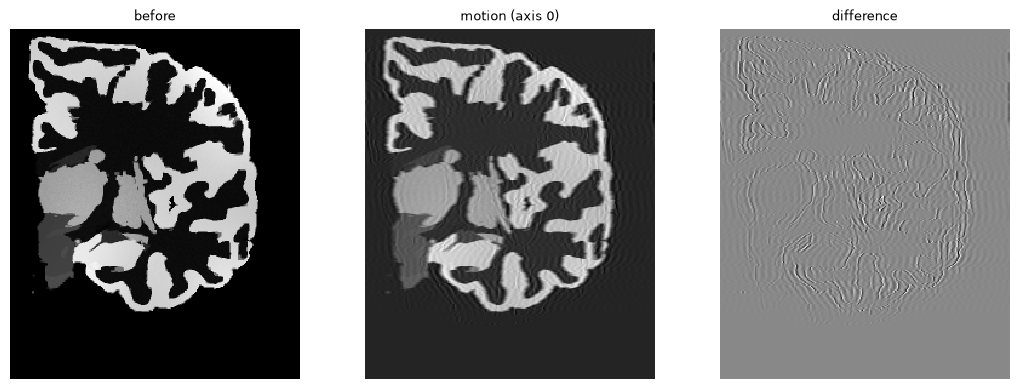

In [4]:
cfgm = load_config(CONFIG, motion={'prob': 1.0, 'translation_mm': [-4, 4]})['motion']
pm = MO.sample(cfgm, np.random.default_rng(2), shape)
print({k: v for k, v in pm.items()})
moved = MO.apply(biased, pm, gen.voxel_mm)
show([biased, moved, moved - biased], ['before', f'motion (axis {pm["axis"]})', 'difference'],
     axis=(pm['axis'] + 1) % 3, size=3.6)

With zero motion the step is the identity (up to FFT rounding):

In [5]:
still = dict(pm, rotation_deg=[[0, 0, 0]] * pm['shots'], translation_mm=[[0, 0, 0]] * pm['shots'])
print('max |difference| with zero motion:', float((MO.apply(biased, still, 0.4) - biased).abs().max()))

max |difference| with zero motion: 1.6395002603530884e-05


In patch mode the motion is simulated on the patch only (ghosts wrap inside the patch): an
approximation, see notebook 10.

## 5c. Resolution

Simulates the acquisition drawn at step 0. On every degraded axis (spacing larger than the
output voxel):

1. blur with the Gaussian slice profile (std `A.sigma_vox(acq, voxel)`, computed from the thickness
   and alpha, notebook 04; kernel truncated at 3 std, edges replicated);
2. downsample to `ceil(n / ratio)` voxels, `ratio = spacing / output voxel` (trilinear);
3. *(optional)* add noise on this low-resolution grid;
4. upsample back to the output grid (trilinear).

It returns the image on the output grid and the image on the low-res grid. With `acq = None`
(or no degraded axis) the image is returned unchanged and the low-res image is `None`.

In [ ]:
acqs = {
    'iso 1.0 mm': dict(A.none_params(0.4), spacing_mm=[1.0] * 3, thickness_mm=[1.0] * 3),
    'aniso z 3 mm': dict(A.none_params(0.4), spacing_mm=[0.4, 0.4, 3.0], thickness_mm=[0.4, 0.4, 3.0]),
}
outs, lows = [], []
for name, acq in acqs.items():
    out, low = RS.apply(clean, acq, gen.voxel_mm)
    outs.append(out); lows.append(low)
    print(f'{name}: low-res grid {tuple(low.shape)} -> back to {tuple(out.shape)}')
show([clean, lows[0], outs[0], lows[1], outs[1]],
     ['clean 0.4 mm', 'iso: low-res grid', 'iso: back on 0.4 mm', 'aniso z: low-res grid', 'aniso z: back'],
     axis=0, size=3)

The tests check this step against v2's `LowResAcquisitionFinalTransform` (max difference < 0.02
away from the borders; only the kernel truncation differs).

## 5d. Noise

`image + sigma * N(0, 1)`, `sigma` drawn per image from `noise.sigma` (on the image divided by
`intensity_scale`, so 0.05 = 5 % of the colour range). The plan stores a seed, not the field.

Where it is added depends on `noise.space`:

| `noise.space` | degraded acquisition | not degraded |
|---|---|---|
| `lowres` (default) | on the low-res grid, inside 5c → upsampled with the image (correlated) | output grid |
| `highres` | on the output grid, before 5c (SynthSeg) → blurred by 5c | output grid |

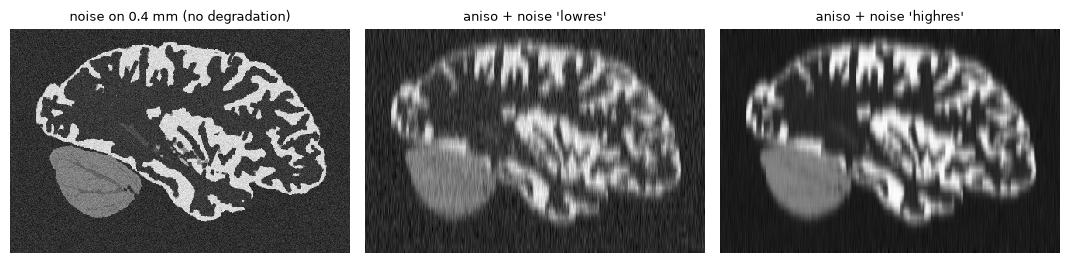

In [7]:
pn = dict(sigma=0.05, seed=1, space='lowres')
acq = acqs['aniso z 3 mm']
low_noise, _ = RS.apply(clean, acq, gen.voxel_mm, noise_fn=lambda x: NZ.apply(x, pn))
high_noise, _ = RS.apply(NZ.apply(clean, pn), acq, gen.voxel_mm)
plain = NZ.apply(clean, pn)
show([plain, low_noise, high_noise],
     ['noise on 0.4 mm (no degradation)', "aniso + noise 'lowres'", "aniso + noise 'highres'"],
     axis=0, size=3.6)

With `lowres`, the noise is drawn on the coarse grid and stretched along z (as in a real
thick-slice scan). With `highres` it is blurred away by the slice profile.

## 6. Normalisation

| method | rule |
|---|---|
| `minmax` | `(x - min) / (max - min)` → [0, 1] |
| `percentile` | clip to the `[p_lo, p_hi]` percentiles, then [0, 1]; robust to a few extreme voxels |
| `none` | unchanged (e.g. when the training pipeline normalises itself) |

It returns the values used (`lo`, `hi`), saved with each image by the CLI.

In [8]:
x = low_noise
for cfgn in [dict(method='minmax'), dict(method='percentile', percentiles=[0.5, 99.5]), dict(method='none')]:
    y, info = NM.apply(x, cfgn)
    print(f'{cfgn["method"]:10s} -> range [{float(y.min()):.3f}, {float(y.max()):.3f}], params {info}')

minmax     -> range [0.000, 1.000], params {'method': 'minmax', 'lo': -0.2626088559627533, 'hi': 1.1037880182266235}
percentile -> range [0.000, 1.000], params {'method': 'percentile', 'lo': -0.10049135982990265, 'hi': 0.8478153347969055}
none       -> range [-0.263, 1.104], params {'method': 'none', 'lo': None, 'hi': None}


**Patch mode:** the min/max of a patch are not those of the whole image, so a patch is normalised
differently from the same crop of a full image. If this matters, use `percentile` or `none`
(nnU-Net applies its own z-score anyway).

## 7. All together, in the pipeline

In [ ]:
g = Generator([TEMPLATE], load_config(CONFIG, motion={'prob': 1.0}, acquisition={'lowres_prob': 1.0}),
              device=DEVICE)
rec = Recorder(steps='all')
s = g(5, recorder=rec)
names = ['synthesis', 'bias', 'motion', 'lowres', 'resolution', 'image']
show([rec.steps[n] for n in names], names, axis=0, size=3)
print('acquisition:', A.describe(s.plan['acquisition'], g.voxel_mm), np.round(s.plan['acquisition']['spacing_mm'], 2).tolist(),
      '| noise sigma', round(s.plan['noise']['sigma'], 3), s.plan['noise']['space'],
      '| normalisation', s.normalization)